<a href="https://colab.research.google.com/github/chodavarapuaruna/Air_Quality_dataset/blob/main/Histogram.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Available columns:
['Date', 'Location', 'PM2_5', 'Air_Quality_category']


/tmp/ipykernel_984/3455818503.py:52: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df[date_col] = pd.to_datetime(df[date_col], errors='coerce')


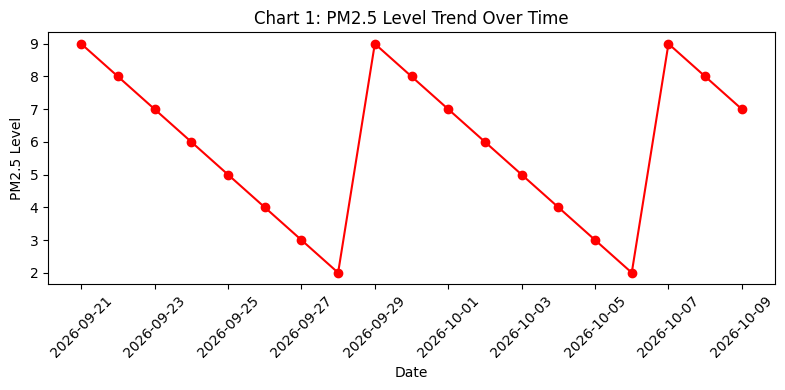

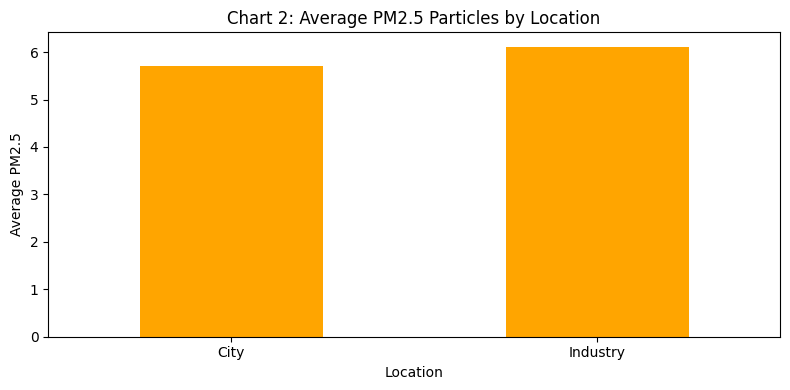

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Load the dataset
file_path = '/content/Air Quality.csv'

if not os.path.exists(file_path):
    from google.colab import files
    uploaded = files.upload()
    file_path = next(iter(uploaded))

df = pd.read_csv(file_path)

# Clean column names
df.columns = df.columns.str.strip()

print("Available columns:")
print(df.columns.tolist())

# Find the required columns automatically
location_col = next(
    (c for c in df.columns if 'location' in c.lower()
     or 'city' in c.lower()), None
)

pm_col = next(
    (c for c in df.columns
     if 'pm2.5' in c.lower().replace('_', '').replace(' ', '')
     or 'pm25' in c.lower().replace('_', '').replace(' ', '')),
    None
)

date_col = next(
    (c for c in df.columns if 'date' in c.lower()
     or 'time' in c.lower()), None
)

# Check whether the columns exist
if pm_col is None:
    print("PM2.5 column not found. Check the column names above.")

elif location_col is None:
    print("Location column not found. Check the column names above.")

else:
    # Convert PM2.5 values to numbers
    df[pm_col] = pd.to_numeric(df[pm_col], errors='coerce')

    # Chart 1: PM2.5 trend over time
    if date_col is not None:
        df[date_col] = pd.to_datetime(df[date_col], errors='coerce')
        city_data = df.dropna(subset=[date_col, pm_col])

        if not city_data.empty:
            plt.figure(figsize=(8, 4))
            plt.plot(
                city_data[date_col],
                city_data[pm_col],
                marker='o',
                color='red'
            )
            plt.title('Chart 1: PM2.5 Level Trend Over Time')
            plt.xlabel('Date')
            plt.ylabel('PM2.5 Level')
            plt.xticks(rotation=45)
            plt.tight_layout()
            plt.show()

    # Chart 2: Average PM2.5 by location
    avg_pollution = df.groupby(location_col)[pm_col].mean().dropna()

    plt.figure(figsize=(8, 4))
    avg_pollution.plot(kind='bar', color='orange')
    plt.title('Chart 2: Average PM2.5 Particles by Location')
    plt.xlabel('Location')
    plt.ylabel('Average PM2.5')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

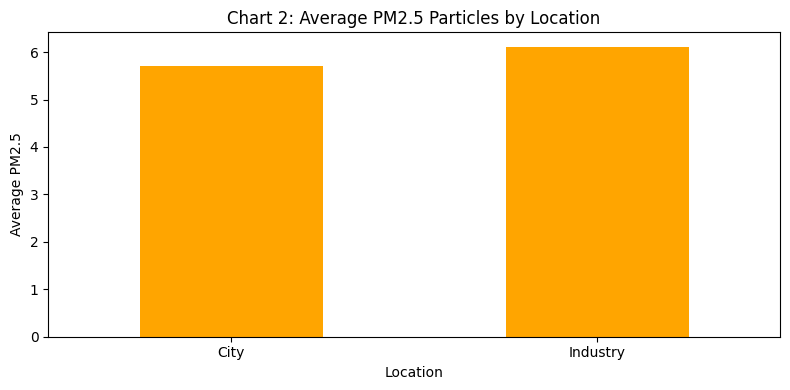

In [13]:
plt.figure(figsize=(8, 4))

avg_pollution.plot(kind='bar', color='orange')

plt.title('Chart 2: Average PM2.5 Particles by Location')
plt.xlabel('Location')
plt.ylabel('Average PM2.5')
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

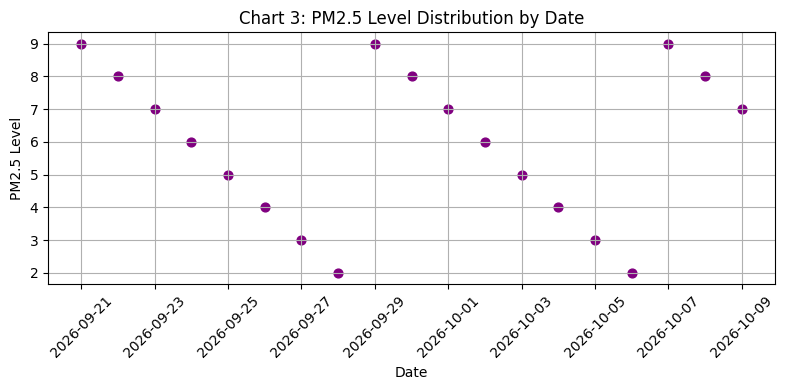

In [16]:
#Chart 3: Scatter Plot

if date_col is not None and pm_col is not None:
    plt.figure(figsize=(8, 4))

    plt.scatter(
        df[date_col],
        df[pm_col],
        color='purple',
        s=40
    )

    plt.title('Chart 3: PM2.5 Level Distribution by Date')
    plt.xlabel('Date')
    plt.ylabel('PM2.5 Level')
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("Date or PM2.5 column was not found.")
    print(df.columns.tolist())

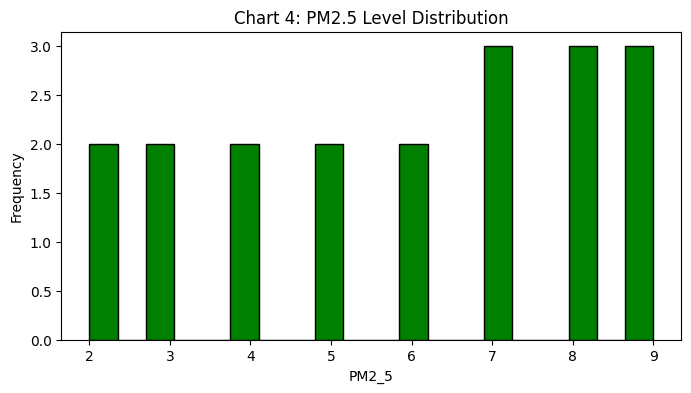

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/content/Air Quality.csv')

#Chart4: Histogram
plt.figure(figsize=(8, 4))
plt.hist(df['PM2_5'], bins=20, color='green', edgecolor='black')
plt.title('Chart 4: PM2.5 Level Distribution')
plt.xlabel('PM2_5')
plt.ylabel('Frequency')
plt.show()

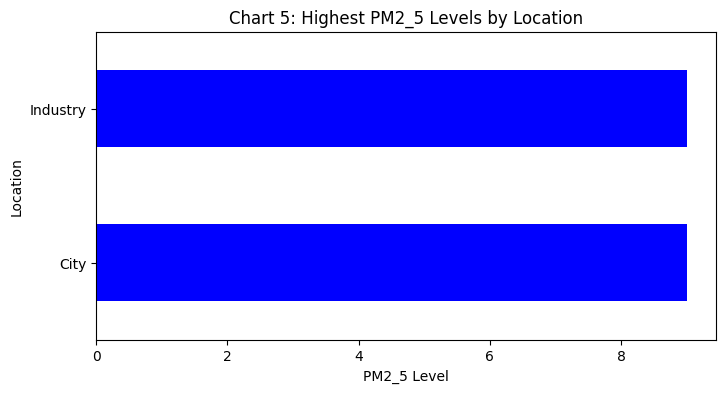

In [22]:
#char5:Horizantal Bar chart
plt.figure(figsize=(8,4))
df.groupby('Location')['PM2_5'].max().plot(kind='barh', color='blue')
plt.title('Chart 5: Highest PM2_5 Levels by Location')
plt.xlabel('PM2_5 Level')
plt.ylabel('Location')
plt.show()

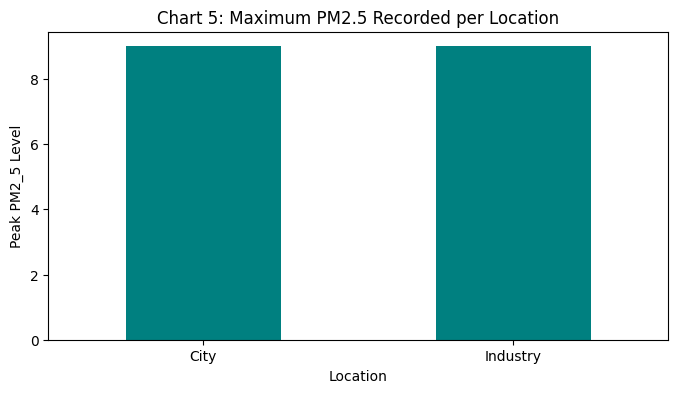

In [24]:
# Chart 6: Vertical Bar Chart (Max PM2.5 recorded per location)
plt.figure(figsize=(8, 4))
df.groupby('Location')['PM2_5'].max().plot(kind='bar', color='teal')
plt.title('Chart 5: Maximum PM2.5 Recorded per Location')
plt.xlabel('Location')
plt.ylabel('Peak PM2_5 Level')
plt.xticks(rotation=0)
plt.show()

In [25]:
# 1. Define the exact text for your Week 2 README file
readme_text = """# Week 2: Data Handling, Visualisation & AI Prompting
## Overview
This folder contains my Week 2 deliverables for the II CSE(AI&ML) – A Department Activity Plan. The primary focus of this week is Exploratory Data Analysis (EDA) on campus energy and city air-quality datasets, alongside AI prompt engineering and collaborative Git workflows.

## Week 2 Deliverables
* **EDA Notebook:** A Google Colab notebook using `pandas` and `matplotlib` that cleans, groups, and filters dataset. It includes 5 labelled charts and 5 written data insights.
* **AI Application Mapping:** Classification of 10 real-world systems into Rule-based, ML, DL, or Generative AI categories.
* **Prompt Engineering Portfolio:** A structured document containing 10 AI prompts (zero-shot, role, constraint, etc.), their outputs, and improvement notes for data-summary tasks.
* **Git Branching:** Proof of 2 branches and 1 merged pull request executed on this repository.

## How to Run the Code in Google Colab
1. Open the `.ipynb` notebook file in this repository.
2. Click the **"Open in Colab"** badge at the top of the file.
3. Ensure the dataset CSV file is uploaded to the Colab session storage before running the cells.
4. Run all cells to generate the 5 data visualisations.

## Technologies Used
* **Python Libraries:** `pandas`, `matplotlib`
* **Tools:** Google Colab, Git, GitHub
"""


# 2. Write the text into a new file named README.md
with open("README.md", "w") as file:
    file.write(readme_text)

# 3. Tell Google Colab to trigger a download of the file to your computer
from google.colab import files
files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>